# Mars weather at Gale Crater: Curiosity REMS analysis
Run with **Restart → Run All**. Cells must run top to bottom.

## 1. Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

CSV_FILE = 'REMS_Mars_Dataset.csv'   # change to your file's actual name

df = pd.read_csv(CSV_FILE)
rows_start = len(df)
print(rows_start, 'rows loaded')
df.head()

3197 rows loaded


,earth_date_time,mars_date_time,sol_number,max_ground_temp(°C),min_ground_temp(°C),max_air_temp(°C),min_air_temp(°C),mean_pressure(Pa),wind_speed(m/h),humidity(%),sunrise,sunset,UV_Radiation,weather
0,"Earth, 2022-01-26 UTC","Mars, Month 6 - LS 163°",Sol 3368,-3,-71,10,-84,707,Value not available,Value not available,05:25,17:20,moderate,Sunny
1,"Earth, 2022-01-25 UTC","Mars, Month 6 - LS 163°",Sol 3367,-3,-72,10,-87,707,Value not available,Value not available,05:25,17:20,moderate,Sunny
2,"Earth, 2022-01-24 UTC","Mars, Month 6 - LS 162°",Sol 3366,-4,-70,8,-81,708,Value not available,Value not available,05:25,17:21,moderate,Sunny
3,"Earth, 2022-01-23 UTC","Mars, Month 6 - LS 162°",Sol 3365,-6,-70,9,-91,707,Value not available,Value not available,05:26,17:21,moderate,Sunny
4,"Earth, 2022-01-22 UTC","Mars, Month 6 - LS 161°",Sol 3364,-7,-71,8,-92,708,Value not available,Value not available,05:26,17:21,moderate,Sunny


## 2. Pull numbers out of the text columns

In [2]:
df['sol'] = df['sol_number'].str.extract(r'(\d+)').astype(int)
df['ls'] = df['mars_date_time'].str.extract(r'LS (\d+)').astype(float)
df['month'] = df['mars_date_time'].str.extract(r'Month (\d+)').astype(float)
df['terrestrial_date'] = pd.to_datetime(
    df['earth_date_time'].str.extract(r'(\d{4}-\d{2}-\d{2})')[0])

## 3. Rename columns, convert to numbers, sort by sol

In [3]:
df = df.rename(columns={
    'min_air_temp(°C)': 'min_temp',
    'max_air_temp(°C)': 'max_temp',
    'min_ground_temp(°C)': 'min_gts_temp',
    'max_ground_temp(°C)': 'max_gts_temp',
    'mean_pressure(Pa)': 'pressure',
    'wind_speed(m/h)': 'wind_speed',
    'humidity(%)': 'humidity',
})

num_cols = ['min_temp', 'max_temp', 'min_gts_temp', 'max_gts_temp',
            'pressure', 'wind_speed', 'humidity']
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors='coerce')  # 'Value not available' -> NaN

df = df.sort_values('sol').reset_index(drop=True)
print('Sols:', df['sol'].min(), 'to', df['sol'].max())

Sols: 1 to 3368


## 4. Count missing values

In [4]:
df[num_cols + ['ls']].isna().sum()

min_temp          29
max_temp          29
min_gts_temp      28
max_gts_temp      28
pressure          27
wind_speed      3197
humidity        3197
ls                 0
dtype: int64

## 5. Drop empty columns and rows with missing core values

In [5]:
df = df.drop(columns=['wind_speed', 'humidity'])   # 100% missing

core = ['min_temp', 'max_temp', 'pressure']
rows_before = len(df)
df = df.dropna(subset=core).reset_index(drop=True)
rows_dropped_missing = rows_before - len(df)

print('Started with:', rows_start)
print('Dropped (missing temp/pressure):', rows_dropped_missing)
print('Remaining:', len(df))

Started with: 3197
Dropped (missing temp/pressure): 29
Remaining: 3168


## 6. Flag sensor glitches with a rolling median and build `clean`
A reading is flagged if it is more than 15 °C (temperatures) or 20 Pa (pressure) from the median of the surrounding 15 sols.

**`clean` is defined here only. No other cell redefines it.**

In [6]:
for col in ['min_temp', 'max_temp', 'pressure']:
    med = df[col].rolling(15, center=True, min_periods=5).median()
    threshold = 15 if 'temp' in col else 20
    df[col + '_outlier'] = (df[col] - med).abs() > threshold
    print(col, df[col + '_outlier'].sum(), 'flagged')

flag_cols = ['min_temp_outlier', 'max_temp_outlier', 'pressure_outlier']
df['any_outlier'] = df[flag_cols].any(axis=1)
print('Sols flagged in at least one column:', df['any_outlier'].sum())

clean = df[~df['any_outlier']].copy()
clean['temp_range'] = clean['max_temp'] - clean['min_temp']
clean['mars_year'] = 31 + (clean['ls'].diff() < -300).cumsum()   # new Mars year each time ls wraps 360 -> 0
print('Final clean dataset:', len(clean), 'sols')

min_temp 40 flagged
max_temp 6 flagged
pressure 7 flagged
Sols flagged in at least one column: 50
Final clean dataset: 3118 sols


## 7. Chart: pressure through the Martian year

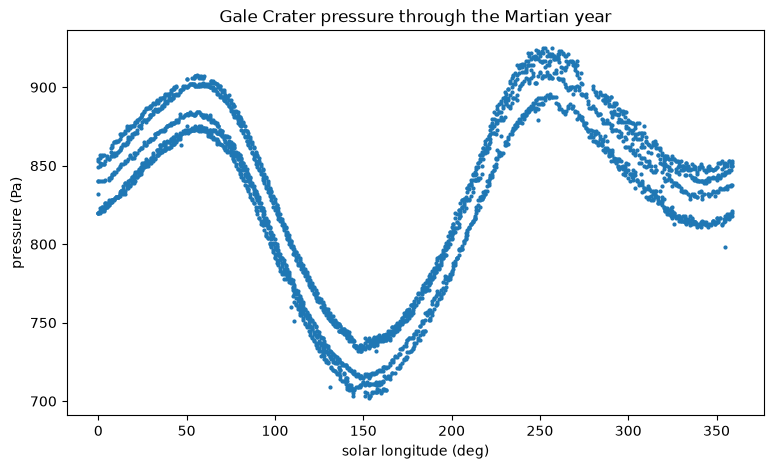

In [7]:
plt.figure(figsize=(9, 5))
plt.scatter(clean['ls'], clean['pressure'], s=4)
plt.xlabel('solar longitude (deg)'); plt.ylabel('pressure (Pa)')
plt.title('Gale Crater pressure through the Martian year')
plt.savefig('pressure_by_ls.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Chart: pressure by Mars year

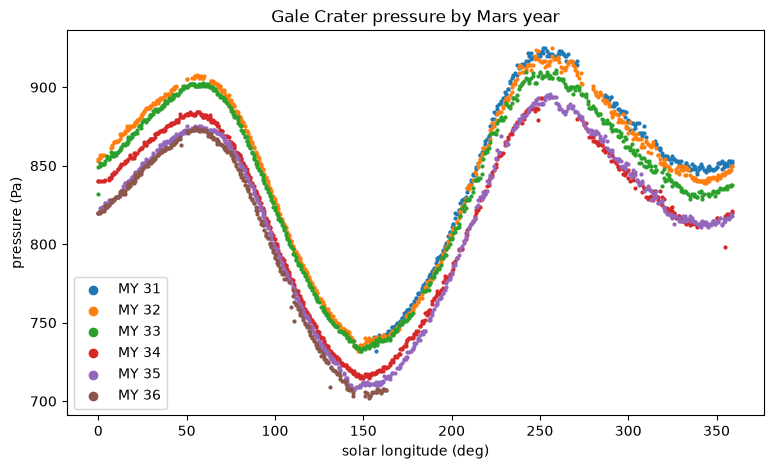

In [8]:
plt.figure(figsize=(9, 5))
for year, grp in clean.groupby('mars_year'):
    plt.scatter(grp['ls'], grp['pressure'], s=4, label=f'MY {year}')
plt.xlabel('solar longitude (deg)'); plt.ylabel('pressure (Pa)')
plt.title('Gale Crater pressure by Mars year')
plt.legend(markerscale=3)
plt.savefig('pressure_by_mars_year.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Chart: pressure over the whole mission

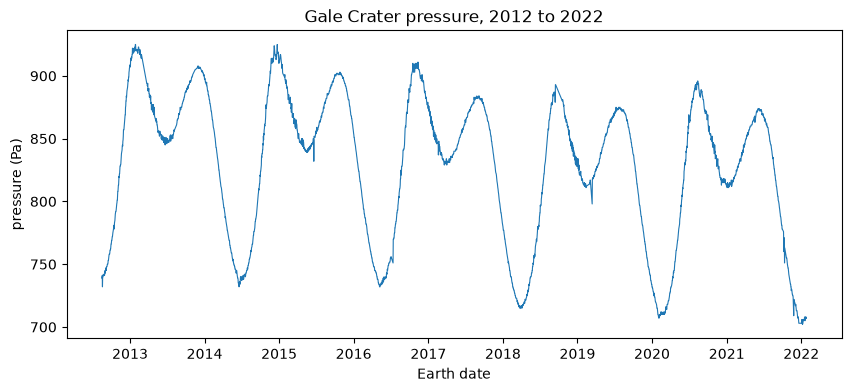

In [9]:
plt.figure(figsize=(10, 4))
plt.plot(clean['terrestrial_date'], clean['pressure'], linewidth=0.8)
plt.xlabel('Earth date'); plt.ylabel('pressure (Pa)')
plt.title('Gale Crater pressure, 2012 to 2022')
plt.savefig('pressure_timeline.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Chart: daily temperature range

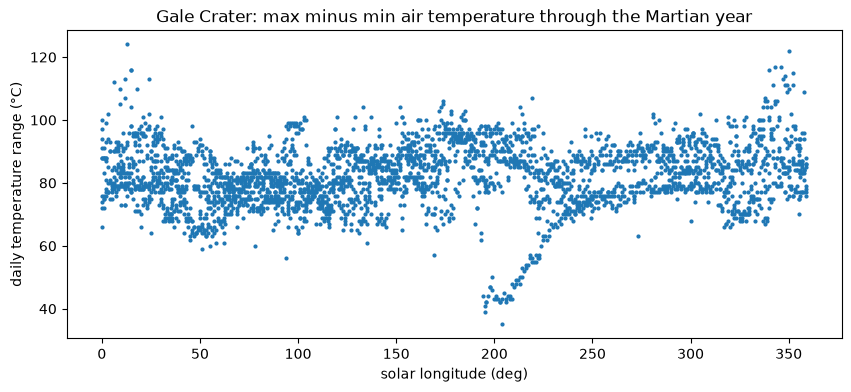

In [10]:
plt.figure(figsize=(10, 4))
plt.scatter(clean['ls'], clean['temp_range'], s=4)
plt.xlabel('solar longitude (deg)'); plt.ylabel('daily temperature range (°C)')
plt.title('Gale Crater: max minus min air temperature through the Martian year')
plt.savefig('temp_range_by_ls.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Check: the 2018 global dust storm

In [11]:
storm = clean[(clean['ls'].between(190, 235)) & (clean['temp_range'] < 55)]
print(len(storm), 'sols, from', storm['terrestrial_date'].min().date(), 'to', storm['terrestrial_date'].max().date())
storm[['terrestrial_date', 'sol', 'ls', 'min_temp', 'max_temp', 'temp_range']]

38 sols, from 2018-06-17 to 2018-07-25


,terrestrial_date,sol,ls,min_temp,max_temp,temp_range
1973,2018-06-17,2084,194.0,-58.0,-14.0,44.0
1974,2018-06-18,2085,195.0,-56.0,-17.0,39.0
1975,2018-06-19,2086,195.0,-58.0,-17.0,41.0
1976,2018-06-20,2087,196.0,-57.0,-15.0,42.0
1977,2018-06-21,2088,196.0,-58.0,-16.0,42.0
1978,2018-06-22,2089,197.0,-59.0,-15.0,44.0
1979,2018-06-23,2090,198.0,-61.0,-14.0,47.0
1980,2018-06-24,2091,198.0,-60.0,-13.0,47.0
1981,2018-06-25,2092,199.0,-62.0,-12.0,50.0
1982,2018-06-26,2093,199.0,-60.0,-14.0,46.0
